## Telco Customer Churn Dataset ##
**Objective**: Predict customer retention based on the customer metadata, like services that each customer has signed up for, customer account and demographic information

## 1. Config and Imports

In [76]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.axes import Axes

In [77]:
pd.set_option('display.max_columns', None)

In [78]:
DATA_PATH = "data/WA_Fn-UseC_-Telco-Customer-Churn.csv"

NUMERIC_COLUMNS = ['tenure', 'MonthlyCharges', 'TotalCharges']

BOOLEAN_COLUMNS = ['SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 
                   'PaperlessBilling']

CATEGORICAL_COLUMNS = ['gender', 'MultipleLines', 'InternetService', 'OnlineSecurity', 
                       'OnlineBackup' ,'Contract', 'PaymentMethod', 'DeviceProtection',
                       'TechSupport', 'StreamingTV', 'StreamingMovies']
TARGET_COLUMN = 'Churn'

## 2. Helper Functions

### 2.1 Read & Overview

In [79]:
def read_data(path: str) -> pd.DataFrame:
    """Reads the data from the given path and returns a pandas DataFrame."""
    return pd.read_csv(path)

In [80]:
def check_data_quality(df: pd.DataFrame) -> pd.DataFrame:
    """Checks the quality of the data and returns a summary table."""
    print(f"Number of rows: {df.shape[0]}")
    print(f"Number of columns: {df.shape[1]}")
    print(f"Duplicated rows: {df.duplicated().sum()}\n")
    
    # Create summary table
    summary = pd.DataFrame({
        'Column': df.columns,
        'Data Type': df.dtypes.values,
        'Missing Values': df.isna().sum().values,
        'Missing %': (df.isna().sum().values / len(df) * 100).round(2),
        'Unique Values': df.nunique().values
    })
    
    return summary

In [81]:
def convert_to_boolean(df: pd.DataFrame, columns: list) -> pd.DataFrame:
    """Converts specified columns in the DataFrame to boolean type."""
    result = df.copy()

    values_mapping = {'Yes': True, 'No': False, 0 : False, 1: True}

    for col in columns:
        if result[col].isin(values_mapping.keys()).all():
            result[col] = result[col].map(values_mapping).astype(bool)
        else:
            raise ValueError(f"Column '{col}' contains values not in the mapping.")
    return result

In [82]:
def convert_to_numeric(df: pd.DataFrame, columns: list) -> pd.DataFrame:
    """Converts specified columns in the DataFrame to numeric type."""

    result = df.copy()

    for col in columns:
        values = result[col].replace(r"^\s*$", np.nan, regex=True)
        result[col] = pd.to_numeric(values, errors="raise")
    return result

### 2.2 Visualizations

In [83]:
def plot_proportion_bar(
    ax: Axes,
    values: pd.Series,
    title: str = "",
):
    """Plot True/False percentages with the sample count in the title."""
    counts = values.value_counts().reindex([True, False], fill_value=0)
    percentages = counts / counts.sum() * 100

    left = 0

    for value, color in [(True, "#6EC18F"), (False, "#EA8686")]:
        width = percentages[value]

        bars = ax.barh(
            y=0,
            width=width,
            left=left,
            height=0.8,
            color=color,
            label=str(value),
        )

        if counts[value] > 0:
            ax.bar_label(
                bars,
                labels=[f"{width:.1f}%"],
                label_type="center",
                fontsize=14,
            )

        left += width

    ax.set_xlim(0, 100)
    ax.set_ylim(-0.5, 0.5)  # Keep the vertical scale fixed.
    ax.set_yticks([])
    ax.set_xlabel("Customers (%)")
    ax.set_title(f"{title} (N={len(values):,})")

## 3. Read & Overview Data ##
Based on information provided in kaggle dataset description:
* **Unique values**: CustomerID
* **Boolean values**: SeniorCitizen, Partner, Dependents, PhoneService, PaperlessBilling

In [84]:
df = read_data(DATA_PATH)
df = convert_to_boolean(df, BOOLEAN_COLUMNS + [TARGET_COLUMN])
df = convert_to_numeric(df, NUMERIC_COLUMNS)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,False,True,False,1,False,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,True,Electronic check,29.85,29.85,False
1,5575-GNVDE,Male,False,False,False,34,True,No,DSL,Yes,No,Yes,No,No,No,One year,False,Mailed check,56.95,1889.50,False
2,3668-QPYBK,Male,False,False,False,2,True,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,True,Mailed check,53.85,108.15,True
3,7795-CFOCW,Male,False,False,False,45,False,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,False,Bank transfer (automatic),42.30,1840.75,False
4,9237-HQITU,Female,False,False,False,2,True,No,Fiber optic,No,No,No,No,No,No,Month-to-month,True,Electronic check,70.70,151.65,True


In [85]:
check_data_quality(df)

Number of rows: 7043
Number of columns: 21
Duplicated rows: 0



,Column,Data Type,Missing Values,Missing %,Unique Values
0,customerID,object,0,0.00,7043
1,gender,object,0,0.00,2
2,SeniorCitizen,bool,0,0.00,2
3,Partner,bool,0,0.00,2
4,Dependents,bool,0,0.00,2
5,tenure,int64,0,0.00,73
6,PhoneService,bool,0,0.00,2
7,MultipleLines,object,0,0.00,3
8,InternetService,object,0,0.00,3
9,OnlineSecurity,object,0,0.00,3


There are **11 missing values** in TotalCharges columns

In [86]:
df[df['TotalCharges'].isna()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,False,True,True,0,False,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,True,Bank transfer (automatic),52.55,NaN,False
753,3115-CZMZD,Male,False,False,True,0,True,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,False,Mailed check,20.25,NaN,False
936,5709-LVOEQ,Female,False,True,True,0,True,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,False,Mailed check,80.85,NaN,False
1082,4367-NUYAO,Male,False,True,True,0,True,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,False,Mailed check,25.75,NaN,False
1340,1371-DWPAZ,Female,False,True,True,0,False,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,False,Credit card (automatic),56.05,NaN,False
3331,7644-OMVMY,Male,False,True,True,0,True,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,False,Mailed check,19.85,NaN,False
3826,3213-VVOLG,Male,False,True,True,0,True,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,False,Mailed check,25.35,NaN,False
4380,2520-SGTTA,Female,False,True,True,0,True,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,False,Mailed check,20.00,NaN,False
5218,2923-ARZLG,Male,False,True,True,0,True,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,True,Mailed check,19.70,NaN,False
6670,4075-WKNIU,Female,False,True,True,0,True,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,False,Mailed check,73.35,NaN,False


In all cases when TotalCharge is nan, the column **tenure** is equal 0. That might indicate a new customer, and in fact TotalCharge should be equal 0. 
* If there are no other cases in which tenure is equal zero, these customers will be treated as new, and TotalCharge will be filled with 0.
* Otherwise these values are missing, and these cases will be excluded

In [87]:
print(f"Number of rows with tenure = 0: {df[df['tenure'] == 0].shape[0]}")

Number of rows with tenure = 0: 11


In [88]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

#### Summary ####
* **TotalCharges** contains 11 missing values, originally represented by whitespaces. All affected customers have tenure (number of months customer was active) is equal 0, therefore these customers are treated as new, and the missing values have been filled with 0.

## 4. EDA ##

### 4.1 Target variable ###

In [89]:
pd.DataFrame({
    "count": df["Churn"].value_counts(),
    "percent": df["Churn"].value_counts(normalize=True).round(4) * 100
})

,count,percent
Churn,,
False,5174,73.46
True,1869,26.54


* Dataset is inbalanced, there are 3 times more examples of customers who stayed
* Data needs to be stratified while splitting to train, validation and test sets

### 4.2 Visualization Check ###

#### 4.2.1 Boolean Values

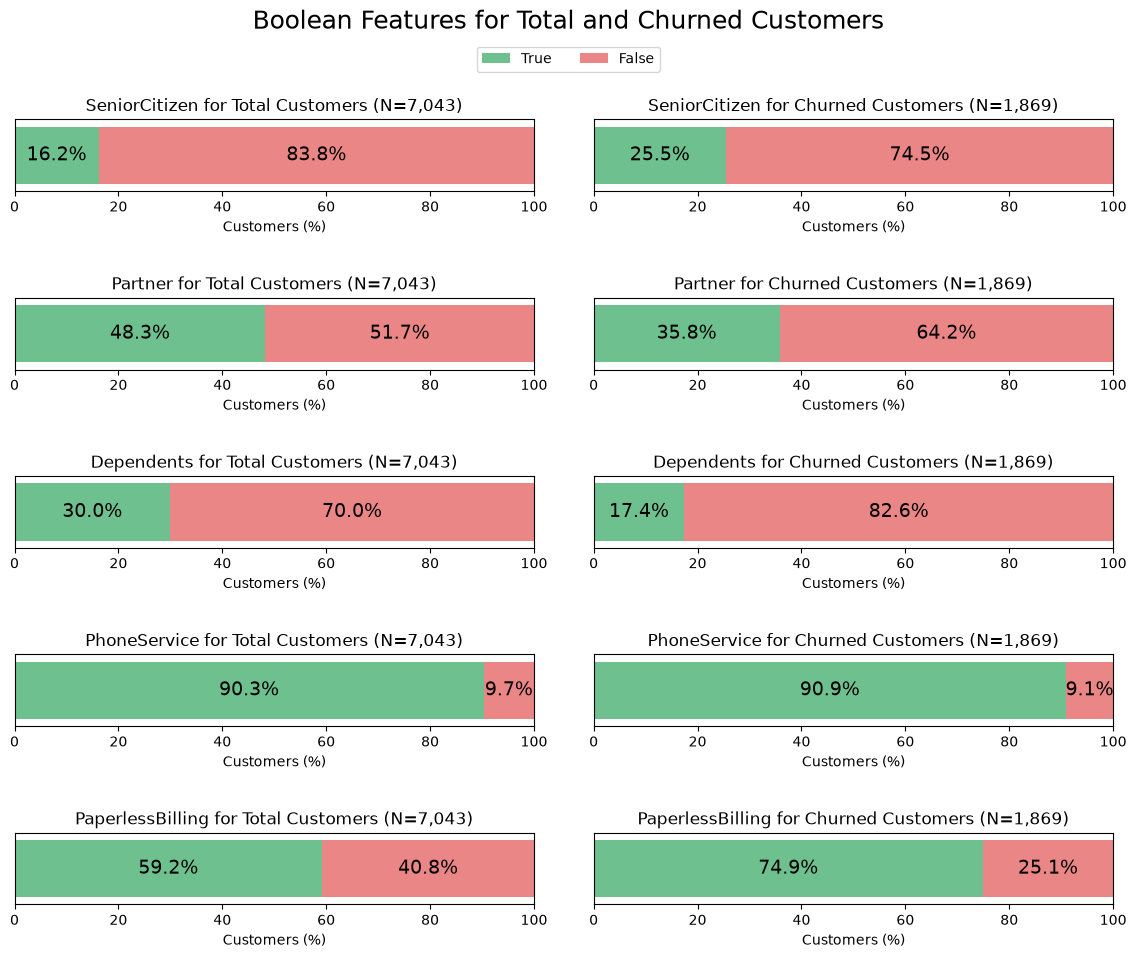

In [94]:
fig, axes = plt.subplots(
    nrows = len(BOOLEAN_COLUMNS),
    ncols = 2,
    figsize = (12, 2 * len(BOOLEAN_COLUMNS)),
    squeeze = False
)

fig.suptitle("Boolean Features for Total and Churned Customers", fontsize=18)

for row, feature in enumerate(BOOLEAN_COLUMNS):
    ax = axes[row, 0]

    plot_proportion_bar(
        ax,
        values = df[feature],
        title = f"{feature} for Total Customers",
    )

    ax = axes[row, 1]

    plot_proportion_bar(
            ax,
            values = df[df['Churn'] == True][feature],
            title = f"{feature} for Churned Customers",
        )
    
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.95),
    ncol=2,
)

plt.tight_layout(pad=3.0)
plt.show()

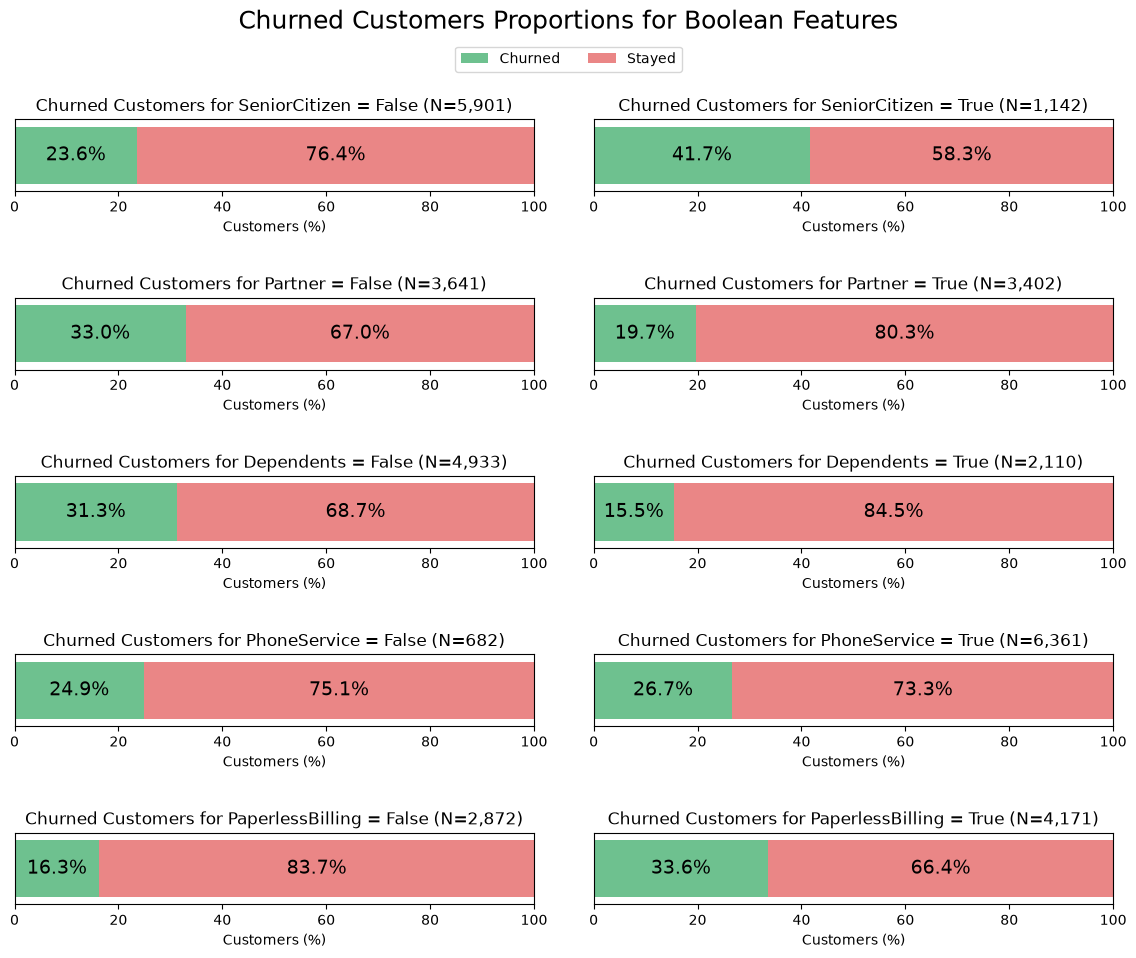

In [97]:
fig, axes = plt.subplots(
    nrows = len(BOOLEAN_COLUMNS),
    ncols = 2,
    figsize = (12, 2 * len(BOOLEAN_COLUMNS)),
    squeeze = False
)

fig.suptitle("Churned Customers Proportions for Boolean Features", fontsize=18)

for row, feature in enumerate(BOOLEAN_COLUMNS):
    ax = axes[row, 0]

    plot_proportion_bar(
        ax,
        values = df[df[feature] == False]['Churn'],
        title = f"Churned Customers for {feature} = False",
    )


    ax = axes[row, 1]

    plot_proportion_bar(
            ax,
            values = df[df[feature] == True]['Churn'],
            title = f"Churned Customers for {feature} = True",
        )

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    ['Churned', 'Stayed'],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.95),
    ncol=2,
)

plt.tight_layout(pad=3.0)
plt.show()

Based on the results above:
* SeniorCitizen, Partner, Dependents, and PaperlessBilling show noticeable differences in their True/False proportions between all customers and churned customers, suggesting associations with churn. PhoneService shows little difference in this comparison. 
* Churn rates are higher among seniors and customers using paperless billing, and lower among customers with partners or dependents. PhoneService shows a comparatively small difference. These are unadjusted associations; predictive usefulness will be assessed during modeling.
</br></br>
Predictive usefulness will be assessed during modeling.

#### 4.2.2 Categorical values